In [2]:
import pandas as pd
import numpy as np
import os
import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:

stead=pd.read_csv('/home/cloudlab/意大利数据集instancegm/Instance.csv')

/tmp/ipykernel_97090/271254483.py:1: DtypeWarning: Columns (23,24,26,27) have mixed types. Specify dtype option on import or set low_memory=False.
  stead=pd.read_csv('/home/cloudlab/意大利数据集instancegm/Instance.csv')


# MOE

In [4]:
phasenet=r'/home/yuan/code/SeisMoE/data/Instance_Predict/Instance_Moe_Predict/picks.csv'
phasenet=pd.read_csv(phasenet)
# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_P_arrival_sample']/2 - merged['p_idx'])
merged['s_error'] = (merged['trace_S_arrival_sample']/2 - merged['s_idx'])


# 选择需要的列
result_moe = merged[['trace_name', 'trace_P_arrival_sample','trace_S_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_moe

,trace_name,trace_P_arrival_sample,trace_S_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket585$1013,:3,:12000",1995,2552.0,588,1266.0,409.5,10.0
1,"bucket1038$363,:3,:12000",1846,NaN,936,1505.0,-13.0,NaN
2,"bucket203$119,:3,:12000",1651,NaN,830,NaN,-4.5,NaN
3,"bucket638$482,:3,:12000",2039,NaN,1018,1193.0,1.5,NaN
4,"bucket934$884,:3,:12000",1982,5948.0,981,2984.0,10.0,-10.0
...,...,...,...,...,...,...,...
116730,"bucket299$368,:3,:12000",1734,2172.0,841,1155.0,26.0,-69.0
116731,"bucket237$752,:3,:12000",3817,4182.0,1899,2088.0,9.5,3.0
116732,"bucket974$786,:3,:12000",1662,2062.0,812,1040.0,19.0,-9.0
116733,"bucket779$427,:3,:12000",1730,1898.0,858,951.0,7.0,-2.0


In [5]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN = 60
result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_TP, 1, 0)
result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_moe.loc[:, 'p_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_FN, 1, 0)
result_moe.loc[:, 's_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result.loc[:, 'p_FP'] = np.where(result['trace_category'] == 'noise', 1, 0)
# result.loc[:, 's_FP'] = np.where(result['trace_category'] == 'noise', 1, 0)



#计算precision，recall，f1
p_TP= result_moe['p_TP'].sum()
s_TP= result_moe['s_TP'].sum()

p_FN= result_moe['p_FN'].sum()
s_FN= result_moe['s_FN'].sum()

#计算FP的数量
p_FP_count = len(stead)*0.106 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
s_FP_count =result_moe.loc[:, 's_FN'].sum()+len(stead)*0.114 - len(phasenet['s_idx'])+phasenet['s_idx'].isna().sum()
# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP

p_FN,p_FP_count = max(p_FN,p_FP_count),min(p_FN,p_FP_count)
s_FN,s_FP_count = max(s_FN,s_FP_count),min(s_FN,s_FP_count)


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

result_table_moe = pd.DataFrame({
    'Moe': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']] = (
    result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 95984
P-FP: 5601
P-FN: 6145.394
P-Precision: 0.9448639070728946
P-Recall: 0.9398273723233881
P-F1 Score: 0.9423389100330337
P-MAE: 0.13780255042507084
P-STD: 0.16409524966906094
S-TP: 65098
S-FP: 5601
S-FN: 22690.386
S-Precision: 0.9207768143820988
S-Recall: 0.741533168180128
S-F1 Score: 0.8214912447354012
S-MAE: 0.099356431841224
S-STD: 0.10589071797427721


/tmp/ipykernel_97090/3600362496.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_97090/3600362496.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_97090/3600362496.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_ind

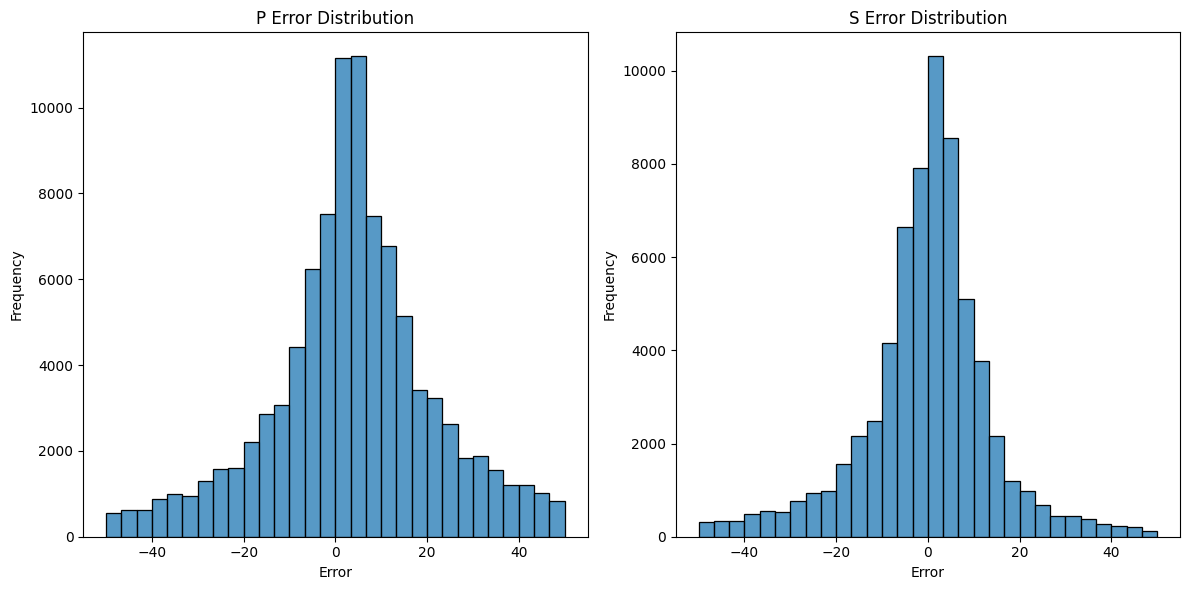

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_moe[result_moe['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_moe[result_moe['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# EQT

In [7]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/Instance_Predict/Instance_EQTransformer_Predict/picks.csv')
# stead=pd.read_csv('/home/cloudlab/意大利数据集instancegm/Instance.csv')
# phasenet=phasenet.loc[:90000]

In [8]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_P_arrival_sample']/2 - merged['p_idx'])
merged['s_error'] = (merged['trace_S_arrival_sample']/2 - merged['s_idx'])


# 选择需要的列
result_eqt = merged[['trace_name', 'trace_P_arrival_sample','trace_S_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_eqt

,trace_name,trace_P_arrival_sample,trace_S_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket1001$102,:3,:12000",2026,2147.0,1012,1070.0,1.0,3.5
1,"bucket1038$671,:3,:12000",1998,2278.0,1000,1140.0,-1.0,-1.0
2,"bucket610$439,:3,:12000",1744,2014.0,891,1013.0,-19.0,-6.0
3,"bucket510$695,:3,:12000",1760,NaN,883,1515.0,-3.0,NaN
4,"bucket382$972,:3,:12000",1948,NaN,1024,2555.0,-50.0,NaN
...,...,...,...,...,...,...,...
98839,"bucket259$473,:3,:12000",3452,NaN,1750,NaN,-24.0,NaN
98840,"bucket1$501,:3,:12000",3145,3300.0,1571,1633.0,1.5,17.0
98841,"bucket345$498,:3,:12000",2005,NaN,1000,1435.0,2.5,NaN
98842,"bucket28$872,:3,:12000",1950,2247.0,974,1113.0,1.0,10.5


In [9]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 50
TP_threshold_S = 30
result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_P, 1, 0)
result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_eqt.loc[:, 'p_FN'] = np.where(abs(result_eqt['p_error']) > 36, 1, 0)
result_eqt.loc[:, 's_FN'] = np.where(abs(result_eqt['s_error']) > 36, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result.loc[:, 'p_FP'] = np.where(result['trace_category'] == 'noise', 1, 0)
# result.loc[:, 's_FP'] = np.where(result['trace_category'] == 'noise', 1, 0)



#计算precision，recall，f1
p_TP= result_eqt['p_TP'].sum()
s_TP= result_eqt['s_TP'].sum()

p_FN= result_eqt['p_FN'].sum()
s_FN= result_eqt['s_FN'].sum()

#计算FP的数量
p_FP_count =len(stead)*0.0919 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
s_FP_count =result_eqt.loc[:, 's_FN'].sum()+len(stead)*0.114 - len(phasenet['s_idx'])+phasenet['s_idx'].isna().sum()
# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP

p_FN,p_FP_count = max(p_FN,p_FP_count),min(p_FN,p_FP_count)
s_FN,s_FP_count = max(s_FN,s_FP_count),min(s_FN,s_FP_count)
# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_eqt.loc[:, 'p_TP_mae'] = np.where(result_eqt['p_TP'] == 1, result_eqt['p_error'], 0)
result_eqt.loc[:, 's_TP_mae'] = np.where(result_eqt['s_TP'] == 1, result_eqt['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_eqt['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_eqt['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_eqt['p_TP_mae'].std() / 100
s_TP_std = result_eqt['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

result_table_eqt = pd.DataFrame({
    'EQT': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']] = (
    result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 92448
P-FP: 7690.983099999998
P-FN: 9186
P-Precision: 0.9231969123121643
P-Recall: 0.9096168604994391
P-F1 Score: 0.9163565763824998
P-MAE: 0.07520178911388023
P-STD: 0.11726043599586661
S-TP: 55025
S-FP: 5388
S-FN: 39375.386
S-Precision: 0.910813897671031
S-Recall: 0.5828895657269876
S-F1 Score: 0.7108558429178726
S-MAE: 0.05888432530667878
S-STD: 0.062401026805258775


/tmp/ipykernel_97090/3014848676.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_97090/3014848676.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_97090/3014848676.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_index

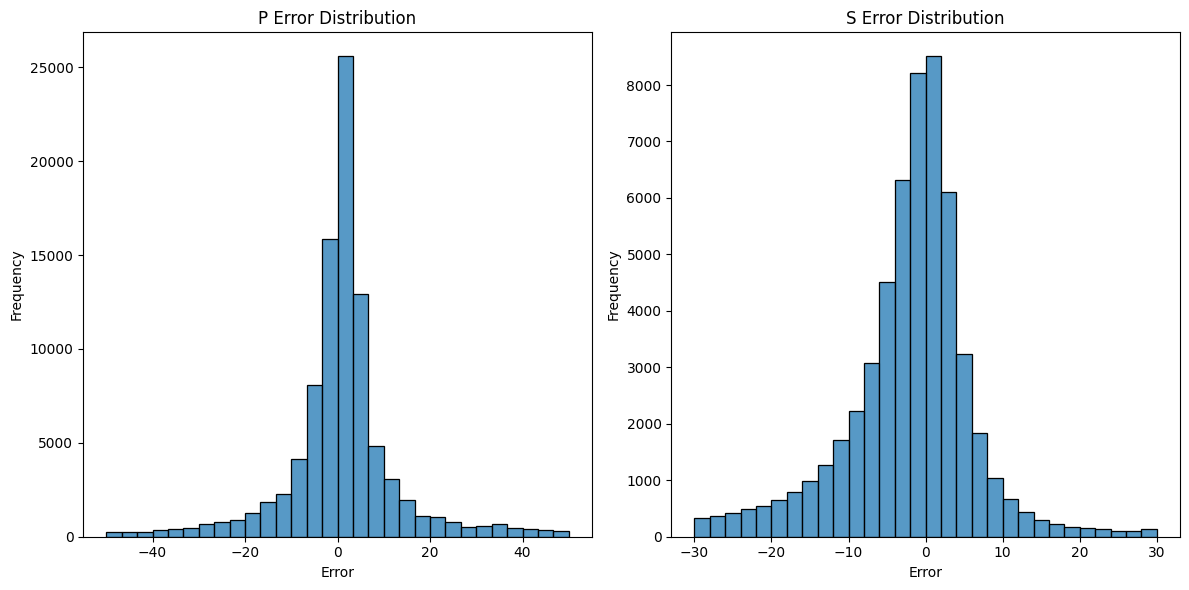

In [10]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_eqt[result_eqt['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_eqt[result_eqt['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# PhaseNet

In [11]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/Instance_Predict/Instance_PhaseNet_Predict/picks.csv')
# phasenet=phasenet.loc[:90000]
# stead=pd.read_csv('/home/cloudlab/意大利数据集instancegm/Instance.csv')

In [12]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_P_arrival_sample']/2 - merged['p_idx'])
merged['s_error'] = (merged['trace_S_arrival_sample']/2 - merged['s_idx'])


# 选择需要的列
result_phasenet = merged[['trace_name', 'trace_P_arrival_sample','trace_S_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_phasenet

,trace_name,trace_P_arrival_sample,trace_S_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket961$1005,:3,:12000",2043,2150.0,1020,1075.0,1.5,0.0
1,"bucket979$76,:3,:12000",2005,NaN,1000,1145.0,2.5,NaN
2,"bucket1079$1015,:3,:12000",1522,2126.0,760,1081.0,1.0,-18.0
3,"bucket356$743,:3,:12000",2081,2349.0,1042,1117.0,-1.5,57.5
4,"bucket564$176,:3,:12000",2381,NaN,1204,1787.0,-13.5,NaN
...,...,...,...,...,...,...,...
106020,"bucket868$55,:3,:12000",2036,NaN,108,1063.0,910.0,NaN
106021,"bucket437$944,:3,:12000",1786,2218.0,892,1083.0,1.0,26.0
106022,"bucket394$225,:3,:12000",2012,3700.0,971,1813.0,35.0,37.0
106023,"bucket285$146,:3,:12000",1930,2173.0,985,1096.0,-20.0,-9.5


In [13]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 50
TP_threshold_S = 50
result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_phasenet.loc[:, 'p_FN'] = np.where(abs(result_phasenet['p_error']) > TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_FN'] = np.where(abs(result_phasenet['s_error']) > TP_threshold_S, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
# result.loc[:, 'p_FP'] = np.where(result['trace_category'] == 'noise', 1, 0)
# result.loc[:, 's_FP'] = np.where(result['trace_category'] == 'noise', 1, 0)



#计算precision，recall，f1
p_TP= result_phasenet['p_TP'].sum()
s_TP= result_phasenet['s_TP'].sum()

p_FN= result_phasenet['p_FN'].sum()
s_FN= result_phasenet['s_FN'].sum()

#计算FP的数量
p_FP_count = len(stead)*0.1 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
s_FP_count =result_phasenet.loc[:, 's_FN'].sum()+ len(stead)*0.114 - len(phasenet['s_idx'])+phasenet['s_idx'].isna().sum()
# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP

p_FN,p_FP_count = max(p_FN,p_FP_count),min(p_FN,p_FP_count)
s_FN,s_FP_count = max(s_FN,s_FP_count),min(s_FN,s_FP_count)
# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

result_table_phasenet = pd.DataFrame({
    'PhaseNet': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})

# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']] = (
    result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 91843
P-FP: 9899.900000000009
P-FN: 14182
P-Precision: 0.9026968958030486
P-Recall: 0.8662390945531714
P-F1 Score: 0.8840922972220442
P-MAE: 0.08297404265975633
P-STD: 0.10557055623497823
S-TP: 58939
S-FP: 6400
S-FN: 34964.386
S-Precision: 0.9020493120494651
S-Recall: 0.6276557482176415
S-F1 Score: 0.7402426135463707
S-MAE: 0.10108586844025179
S-STD: 0.09644408195020528


/tmp/ipykernel_97090/1931756893.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_97090/1931756893.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_97090/1931756893.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[r

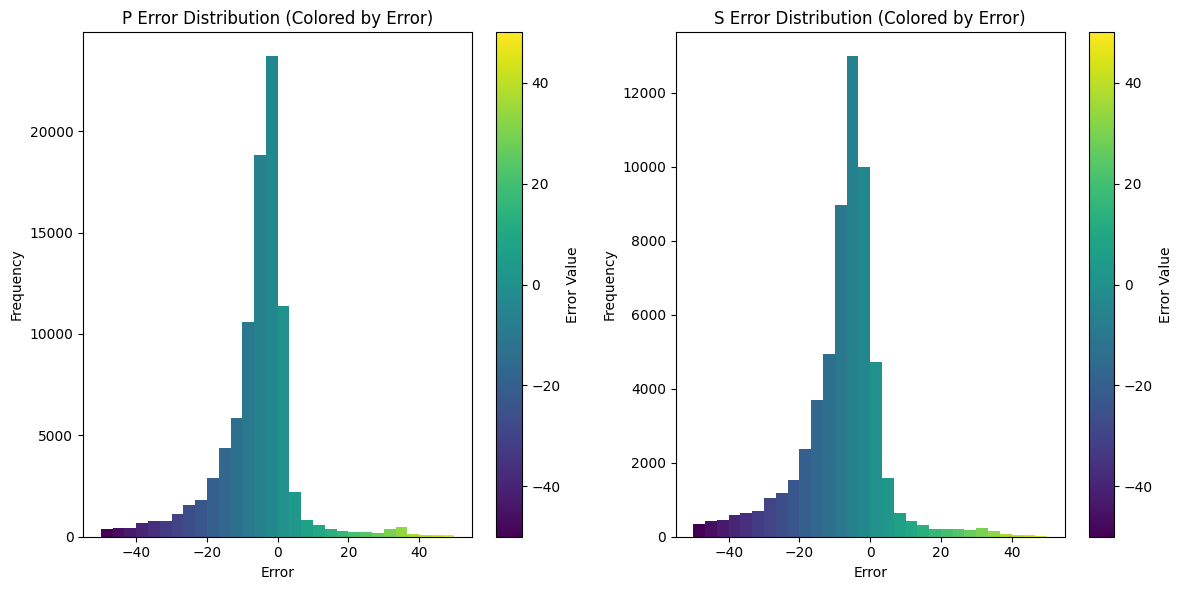

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

plt.figure(figsize=(12, 6))

# ---------------------------
# P 误差分布（横坐标误差值映射到颜色）
# ---------------------------
plt.subplot(1, 2, 1)
p_data = result_phasenet[result_phasenet['p_TP'] == 1]['p_error']
counts, bins, patches = plt.hist(p_data, bins=30)

# 颜色映射：根据误差值（bins）设置颜色
norm = Normalize(vmin=bins.min(), vmax=bins.max())  # 颜色范围 = 误差范围
cmap = cm.viridis
for bin_val, patch in zip(bins[:-1], patches):  # bins[:-1] 是每个柱的左边界
    patch.set_facecolor(cmap(norm(bin_val)))

# 添加色标
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, label='Error Value', ax=plt.gca())  # ax=plt.gca() 指定当前子图
plt.title('P Error Distribution (Colored by Error)')
plt.xlabel('Error')
plt.ylabel('Frequency')

# ---------------------------
# S 误差分布（横坐标误差值映射到颜色）
# ---------------------------
plt.subplot(1, 2, 2)
s_data = result_phasenet[result_phasenet['s_TP'] == 1]['s_error']
counts, bins, patches = plt.hist(s_data, bins=30)

# 颜色映射
norm = Normalize(vmin=bins.min(), vmax=bins.max())
cmap = cm.viridis
for bin_val, patch in zip(bins[:-1], patches):
    patch.set_facecolor(cmap(norm(bin_val)))

# 添加色标
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, label='Error Value', ax=plt.gca())
plt.title('S Error Distribution (Colored by Error)')
plt.xlabel('Error')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# Results

In [15]:
import pandas as pd


# 2) Moe 表同理
df_moe = result_table_moe.set_index('Moe')
df_moe.columns = pd.MultiIndex.from_tuples([('Moe', col) for col in df_moe.columns])

# 1) 以 EQT 表举例
df_eqt = result_table_eqt.set_index('EQT')
# 将原本的列 ['P', 'S'] 改成多层索引：最上层 'EQT'，第二层保持原列名
df_eqt.columns = pd.MultiIndex.from_tuples([('EQT', col) for col in df_eqt.columns])


# 3) PhaseNet 表
df_phasenet = result_table_phasenet.set_index('PhaseNet')
df_phasenet.columns = pd.MultiIndex.from_tuples([('PhaseNet', col) for col in df_phasenet.columns])

# 4) 横向合并
df_multi = pd.concat([df_moe,df_eqt, df_phasenet], axis=1)

print('-----------------------------------Instance----------------------------------------------')
df_multi


-----------------------------------Instance----------------------------------------------


Moe                         EQT                \
                      P             S             P             S   
TP         95984.000000  65098.000000  92448.000000  55025.000000   
FP          5601.000000   5601.000000   7690.000000   5388.000000   
FN          6145.000000  22690.000000   9186.000000  39375.000000   
Precision      0.944864      0.920777      0.923197      0.910814   
Recall         0.939827      0.741533      0.909617      0.582890   
F1 Score       0.942339      0.821491      0.916357      0.710856   
MAE            0.137803      0.099356      0.075202      0.058884   
STD            0.164095      0.105891      0.117260      0.062401   

               PhaseNet                
                      P             S  
TP         91843.000000  58939.000000  
FP          9899.000000   6400.000000  
FN         14182.000000  34964.000000  
Precision      0.902697      0.902049  
Recall         0.866239      0.627656  
F1 Score       0.884092      0.740243  
MAE            0.082974      0.101086  
STD            0.105571      0.096444

# Figure

In [16]:
# import h5py
# import pandas as pd
# import matplotlib.pyplot as plt
# import os

# # 输入路径
# hd = '/home/cloudlab/意大利数据集instancegm/Instance.hdf5'
# output_dir = '/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/Figure/output_waveforms_Instance/'
# os.makedirs(output_dir, exist_ok=True)

# # ===== 读取数据并求交集 =====
# # 筛选 P/S 都为 TP 的 trace_name
# eqt_tp = result_eqt[(result_eqt['p_TP'] == 1) & (result_eqt['s_TP'] == 1)]['trace_name']
# moe_tp = result_moe[(result_moe['p_TP'] == 1) & (result_moe['s_TP'] == 1)]['trace_name']
# phasenet_tp = result_phasenet[(result_phasenet['p_TP'] == 1) & (result_phasenet['s_TP'] == 1)]['trace_name']
# common_traces = set(eqt_tp) & set(moe_tp) & set(phasenet_tp)

# # 筛选出三组数据对应的行
# df_eqt = result_eqt[result_eqt['trace_name'].isin(common_traces)].copy()
# df_moe = result_moe[result_moe['trace_name'].isin(common_traces)].copy()
# df_phasenet = result_phasenet[result_phasenet['trace_name'].isin(common_traces)].copy()

# # 设置索引，便于 trace_name 访问
# moe_dict = df_moe.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# phasenet_dict = df_phasenet.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# num_samples = min(len(df_eqt), 100)
# df_eqt_sampled = df_eqt.sample(n=num_samples, random_state=42).copy()

# print(f"samples:{len(df_eqt_sampled)}")
# # ===== 读取波形并绘图 =====
# with h5py.File(hd, 'r') as f:
#     for i, row in df_eqt_sampled.iterrows():

#         trace_name = row['trace_name']
#         try:
#             group = trace_name.split('$')[0].strip()
#             index = int(trace_name.split('$')[1].split(',')[0].strip())
#             data = f['data'][group][()]  # shape: (3, 6000)
#             data=data[index, :, :].astype(np.float32)
#         except KeyError:
#             print(f"[WARN] Missing trace: {trace_name}")
#             continue

#         z, n, e = data[0,:], data[1,:], data[2,:]

#         from scipy.signal import decimate
#         z = decimate(data[0], 2, ftype='iir', zero_phase=True)
#         n = decimate(data[1], 2, ftype='iir', zero_phase=True)
#         e = decimate(data[2], 2, ftype='iir', zero_phase=True)

#         p_arrival = row['trace_P_arrival_sample']/2
#         s_arrival = row['trace_S_arrival_sample']/2
#         p_eqt = row['p_idx']
#         s_eqt = row['s_idx']
#         p_moe = moe_dict[trace_name]['p_idx']
#         s_moe = moe_dict[trace_name]['s_idx']
#         p_phase = phasenet_dict[trace_name]['p_idx']
#         s_phase = phasenet_dict[trace_name]['s_idx']

#         fig, axs = plt.subplots(5, 1, figsize=(12, 10), sharex=False)
#         components = [z, n, e]
#         labels = ['Z', 'N', 'E']

#         for idx, (ax, comp, label) in enumerate(zip(axs[:3], components, labels)):
#             ax.plot(comp, label=f'{label} component')

#             # 到时标注
#             ax.axvline(p_arrival, color='green', linestyle='--', label='P Arrival')
#             ax.axvline(s_arrival, color='blue', linestyle='--', label='S Arrival')
#             ax.axvline(p_eqt, color='red', linestyle=':', label='EQT P')
#             ax.axvline(s_eqt, color='purple', linestyle=':', label='EQT S')
#             ax.axvline(p_moe, color='orange', linestyle=':', label='Moe P')
#             ax.axvline(s_moe, color='brown', linestyle=':', label='Moe S')
#             ax.axvline(p_phase, color='pink', linestyle='--', label='PhaseNet P')
#             ax.axvline(s_phase, color='cyan', linestyle='--', label='PhaseNet S')

#             ax.set_ylabel(label)
#             ax.legend(loc='upper right', fontsize=8)

#         # 第四图：P 波放大图（Z）
#         start_p = max(0, int(min(p_arrival, p_eqt, p_moe, p_phase) - 50))
#         end_p = min(6000, int(max(p_arrival, p_eqt, p_moe, p_phase) + 50))
#         axs[3].plot(z[start_p:end_p], label='Z (P Zoom)')
#         axs[3].axvline(p_arrival - start_p, color='black', linestyle='--', label='P Arrival')
#         axs[3].axvline(p_eqt - start_p, color='green', linestyle=':', label='EQT P')
#         axs[3].axvline(p_moe - start_p, color='red', linestyle=':', label='Moe P')
#         axs[3].axvline(p_phase - start_p, color='orange', linestyle='--', label='PhaseNet P')
#         axs[3].legend(loc='upper right', fontsize=8)
#         axs[3].set_ylabel('Z (P Zoom)')

#         # 第五图：S 波放大图（Z）
#         start_s = max(0, int(min(s_arrival, s_eqt, s_moe, s_phase) - 50))
#         end_s = min(6000, int(max(s_arrival, s_eqt, s_moe, s_phase) + 50))
#         axs[4].plot(z[start_s:end_s], label='Z (S Zoom)')
#         axs[4].axvline(s_arrival - start_s, color='black', linestyle='--', label='S Arrival')
#         axs[4].axvline(s_eqt - start_s, color='green', linestyle=':', label='EQT S')
#         axs[4].axvline(s_moe - start_s, color='red', linestyle=':', label='Moe S')
#         axs[4].axvline(s_phase - start_s, color='orange', linestyle='--', label='PhaseNet S')
#         axs[4].legend(loc='upper right', fontsize=8)
#         axs[4].set_ylabel('Z (S Zoom)')

#         # 保存图像
#         fig.suptitle(f'Trace: {trace_name}', fontsize=14)
#         plt.tight_layout(rect=[0, 0.03, 1, 0.95])
#         out_path = os.path.join(output_dir, f'{trace_name}.png')
#         plt.savefig(out_path)
#         plt.close(fig)
